## 1. Imports and device



In [ ]:
# Course-aligned imports
# The structure follows the PyTorch/skimage/sklearn approach used in the supplied CSE428 labs.
import os
import random
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skimage
from skimage import io, transform

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cpu


## 2. Reproducibility, Google Drive and checkpoint directory



In [ ]:
# Reproducibility
SEED = 428

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()

# We save checkpoints to Google Drive so training can be resumed in a new Colab session.
# Run this cell in Colab. If Drive mounting is unavailable, the code falls back to /content.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT_DIR = Path("/content/drive/MyDrive/CSE428_Oxford_Pets")
except Exception:
    ROOT_DIR = Path("/content/CSE428_Oxford_Pets")

DATA_DIR = ROOT_DIR / "data"
CHECKPOINT_DIR = ROOT_DIR / "checkpoints"
RESULT_DIR = ROOT_DIR / "results"
DATA_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT_DIR:", ROOT_DIR)
print("CHECKPOINT_DIR:", CHECKPOINT_DIR)


Mounted at /content/drive
ROOT_DIR: /content/drive/MyDrive/CSE428_Oxford_Pets
CHECKPOINT_DIR: /content/drive/MyDrive/CSE428_Oxford_Pets/checkpoints


## 3. Download and extract Oxford-IIIT Pet

In [ ]:
# Download the official Oxford-IIIT Pet images and annotations.
# The assignment explicitly allows alternate mirrors, but the official source is used here.
images_tar = DATA_DIR / "images.tar.gz"
annotations_tar = DATA_DIR / "annotations.tar.gz"
images_dir = DATA_DIR / "images"
annotations_dir = DATA_DIR / "annotations"

def download_file(url, destination):
    if not destination.exists():
        print("Downloading:", url)
        urllib.request.urlretrieve(url, destination)
    else:
        print("Already exists:", destination)

download_file(
    "https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz",
    images_tar
)
download_file(
    "https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz",
    annotations_tar
)

if not images_dir.exists():
    print("Extracting images...")
    with tarfile.open(images_tar, "r:gz") as tar:
        tar.extractall(DATA_DIR)

if not annotations_dir.exists():
    print("Extracting annotations...")
    with tarfile.open(annotations_tar, "r:gz") as tar:
        tar.extractall(DATA_DIR)

print("Images:", images_dir)
print("Annotations:", annotations_dir)


Already exists: /content/drive/MyDrive/CSE428_Oxford_Pets/data/images.tar.gz
Already exists: /content/drive/MyDrive/CSE428_Oxford_Pets/data/annotations.tar.gz
Images: /content/drive/MyDrive/CSE428_Oxford_Pets/data/images
Annotations: /content/drive/MyDrive/CSE428_Oxford_Pets/data/annotations


## 4. Load images, trimaps and class labels

In [ ]:
# Read Oxford-IIIT Pet file names, class IDs and segmentation trimaps.
# list.txt contains the breed/class ID for each image.
list_file = annotations_dir / "list.txt"
trimap_dir = annotations_dir / "trimaps"

rows = []
with open(list_file, "r") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        parts = line.split()
        image_name = parts[0]
        class_id = int(parts[1]) - 1  # convert 1..37 to 0..36
        species_id = int(parts[2])
        breed_id = int(parts[3])
        rows.append((image_name, class_id, species_id, breed_id))

df = pd.DataFrame(rows, columns=["image_name", "class_id", "species_id", "breed_id"])
df["image_path"] = df["image_name"].map(lambda x: str(images_dir / (x + ".jpg")))
df["trimap_path"] = df["image_name"].map(lambda x: str(trimap_dir / (x + ".png")))

print("Total images:", len(df))
print("Number of classes:", df["class_id"].nunique())
print(df.head())


Total images: 7349
Number of classes: 37
       image_name  class_id  species_id  breed_id  \
0  Abyssinian_100         0           1         1   
1  Abyssinian_101         0           1         1   
2  Abyssinian_102         0           1         1   
3  Abyssinian_103         0           1         1   
4  Abyssinian_104         0           1         1   

                                          image_path  \
0  /content/drive/MyDrive/CSE428_Oxford_Pets/data...   
1  /content/drive/MyDrive/CSE428_Oxford_Pets/data...   
2  /content/drive/MyDrive/CSE428_Oxford_Pets/data...   
3  /content/drive/MyDrive/CSE428_Oxford_Pets/data...   
4  /content/drive/MyDrive/CSE428_Oxford_Pets/data...   

                                         trimap_path  
0  /content/drive/MyDrive/CSE428_Oxford_Pets/data...  
1  /content/drive/MyDrive/CSE428_Oxford_Pets/data...  
2  /content/drive/MyDrive/CSE428_Oxford_Pets/data...  
3  /content/drive/MyDrive/CSE428_Oxford_Pets/data...  
4  /content/drive/MyDrive/CS

## 5. Convert trimap boundary pixels to foreground

**Required assignment rule:** Oxford trimaps use 1=foreground, 2=background, 3=boundary. We therefore use `trimap != 2`, making both foreground and boundary pixels foreground.

In [ ]:
# Oxford trimap values:
# 1 = foreground, 2 = background, 3 = boundary.
# Assignment requirement: boundary/unclassified pixels must become foreground.
# Therefore every pixel whose trimap is NOT background (2) becomes foreground.
def trimap_to_foreground(trimap):
    trimap = np.asarray(trimap)
    return (trimap != 2).astype(np.float32)

# Sanity check on one sample.
sample_trim = io.imread(df.iloc[0]["trimap_path"])
binary_sample = trimap_to_foreground(sample_trim)

print("Trimap unique values:", np.unique(sample_trim))
print("Binary mask unique values:", np.unique(binary_sample))


Trimap unique values: [1 2 3]
Binary mask unique values: [0. 1.]


## 6. Common preprocessing + required 3×3 random visualization

All images are resized to 256×256. The mask uses nearest-neighbor-style resizing (`order=0`) so mask labels are not blurred. We retain RGB because breed classification can benefit from color information.

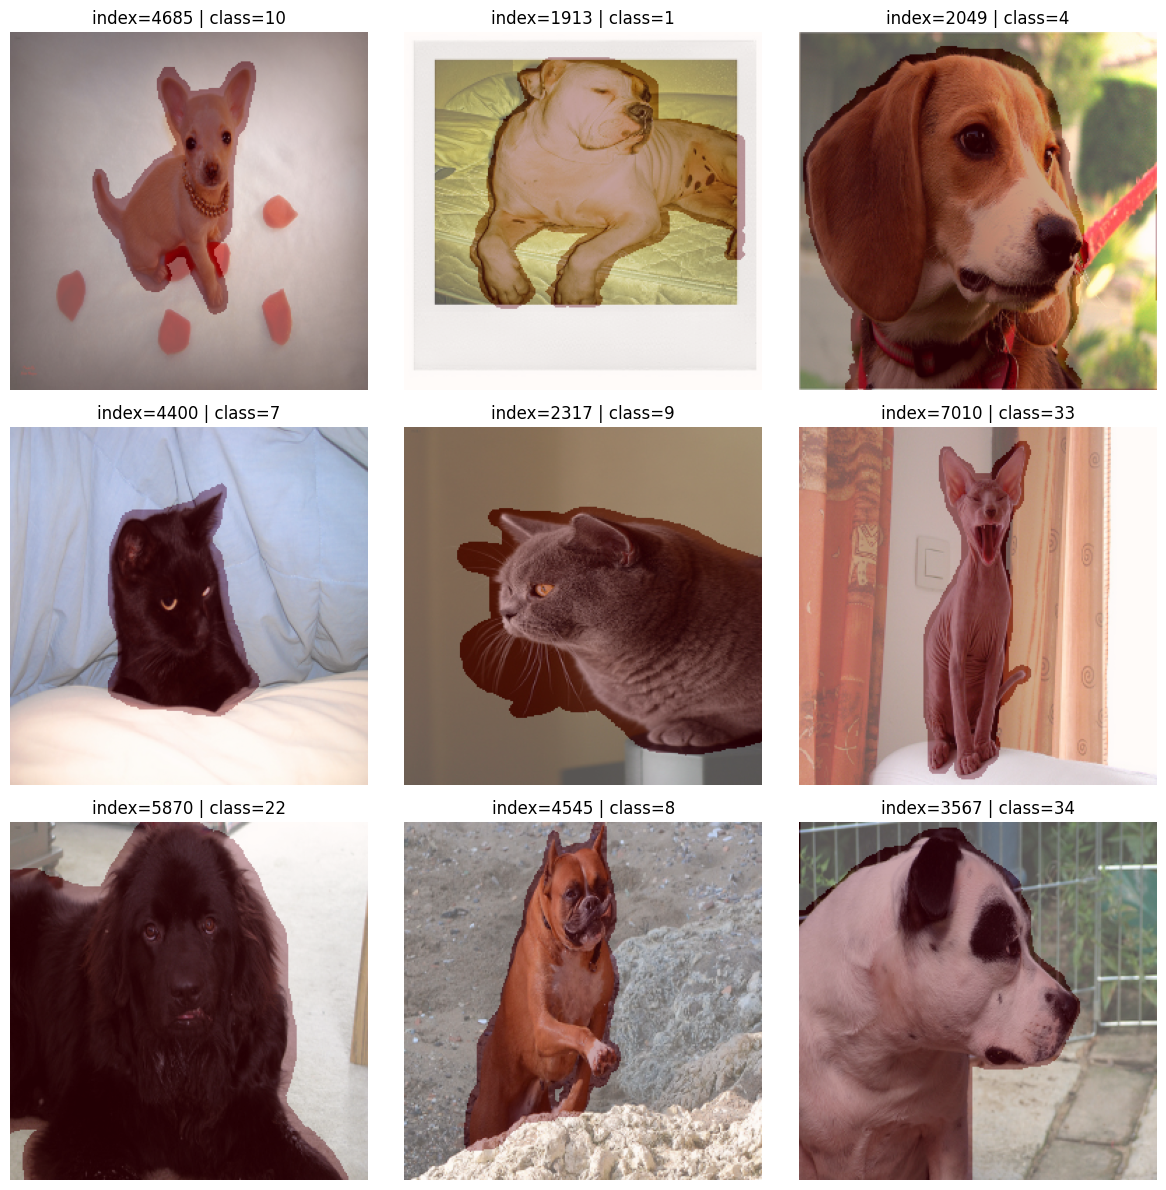

In [ ]:
def load_pair(row, image_size=(256, 256)):
    image = io.imread(row["image_path"])
    if image.ndim == 2:
        image = np.stack([image] * 3, axis=-1)
    image = image[..., :3].astype(np.float32) / 255.0

    trimap = io.imread(row["trimap_path"])
    mask = trimap_to_foreground(trimap)

    image = transform.resize(
        image, (*image_size, 3),
        anti_aliasing=True,
        preserve_range=True
    ).astype(np.float32)

    mask = transform.resize(
        mask, image_size,
        anti_aliasing=False,
        order=0,
        preserve_range=True
    ).astype(np.float32)
    mask = (mask >= 0.5).astype(np.float32)

    return image, mask

def show_overlay(image, mask, title="", alpha=0.35):
    plt.imshow(image)
    plt.imshow(mask, cmap="Reds", alpha=alpha)
    plt.axis("off")
    plt.title(title)

def plot_random_9(df, seed=None):
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(df), size=9, replace=False)

    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    for ax, idx in zip(axes.flat, indices):
        image, mask = load_pair(df.iloc[idx])
        ax.imshow(image)
        ax.imshow(mask, cmap="Reds", alpha=0.35)
        ax.axis("off")
        ax.set_title(f"index={idx} | class={df.iloc[idx]['class_id']}")
    plt.tight_layout()
    plt.show()

plot_random_9(df, seed=SEED)


## 7. Train / validation / test split



In [ ]:
# Stratified train/validation/test split.
# This follows the stratified split idea from Lab 8, but adds a validation set because
# the assignment explicitly requires train, validation and test reporting.
indices = np.arange(len(df))
labels = df["class_id"].to_numpy()

train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.15,
    stratify=labels,
    random_state=SEED
)

train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.1764705882,  # 15% of the full dataset -> about 15% validation
    stratify=labels[train_val_idx],
    random_state=SEED
)

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))


Train: 5143
Validation: 1103
Test: 1103


## 8. Mini-batch loader + augmentation



In [ ]:
# A course-style batch loader, adapted from Lab 8.
# Images and masks are loaded on demand, so the complete dataset does not have to
# sit in GPU memory.
class OxfordPetBatchLoader:
    def __init__(
        self, df, indices, batch_size=8, shuffle=True,
        image_size=(256, 256), augment=False, device="cpu"
    ):
        self.df = df.reset_index(drop=True)
        self.indices = np.asarray(indices)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.image_size = image_size
        self.augment = augment
        self.device = device
        self.order = np.arange(len(self.indices))
        self.iter = 0
        self._reshuffle()

    @property
    def len(self):
        return int(np.ceil(len(self.indices) / self.batch_size))

    def _reshuffle(self):
        if self.shuffle:
            np.random.shuffle(self.order)

    def reset(self):
        self.iter = 0
        if self.shuffle:
            self._reshuffle()

    def next(self):
        start = self.iter * self.batch_size
        end = min(start + self.batch_size, len(self.indices))
        local_ids = self.order[start:end]
        real_ids = self.indices[local_ids]

        images, masks, labels = [], [], []

        for idx in real_ids:
            image, mask = load_pair(self.df.iloc[idx])

            # Synchronized geometric augmentation.
            if self.augment and np.random.rand() < 0.5:
                image = np.fliplr(image).copy()
                mask = np.fliplr(mask).copy()

            # Mild image-only intensity augmentation.
            if self.augment:
                if np.random.rand() < 0.30:
                    image = np.clip(image * np.random.uniform(0.85, 1.15), 0, 1)
                if np.random.rand() < 0.20:
                    noise = np.random.normal(0, 0.02, image.shape).astype(np.float32)
                    image = np.clip(image + noise, 0, 1)

            images.append(image)
            masks.append(mask)
            labels.append(int(self.df.iloc[idx]["class_id"]))

        self.iter += 1
        if self.iter >= self.len:
            self.iter = 0
            if self.shuffle:
                self._reshuffle()

        x = torch.tensor(np.stack(images), dtype=torch.float32, device=self.device)
        y_label = torch.tensor(labels, dtype=torch.long, device=self.device)
        y_mask = torch.tensor(np.stack(masks), dtype=torch.float32, device=self.device)

        # HWC -> BCHW
        x = x.permute(0, 3, 1, 2)
        return x, y_label, y_mask


## 9. Segmentation metrics and Dice loss

The notebook reports the required **mIoU, Dice coefficient and pixel accuracy**. mIoU is the mean of foreground IoU and background IoU.

In [ ]:
def binary_segmentation_metrics(logits, targets, threshold=0.5, eps=1e-7):
    probs = torch.sigmoid(logits)
    preds = (probs >= threshold).float()

    preds = preds.view(preds.shape[0], -1)
    targets = targets.view(targets.shape[0], -1)

    tp = (preds * targets).sum(dim=1)
    fp = (preds * (1 - targets)).sum(dim=1)
    fn = ((1 - preds) * targets).sum(dim=1)
    tn = ((1 - preds) * (1 - targets)).sum(dim=1)

    fg_iou = (tp + eps) / (tp + fp + fn + eps)
    bg_iou = (tn + eps) / (tn + fp + fn + eps)
    miou = ((fg_iou + bg_iou) / 2).mean()

    dice = ((2 * tp + eps) / (2 * tp + fp + fn + eps)).mean()
    pixel_acc = ((tp + tn + eps) / (tp + tn + fp + fn + eps)).mean()

    return miou.item(), dice.item(), pixel_acc.item()

class DiceLoss(nn.Module):
    def __init__(self, epsilon=1.0):
        super().__init__()
        self.epsilon = epsilon

    def forward(self, preds, targets):
        preds = torch.sigmoid(preds)
        intersection = (preds * targets).sum()
        return 1 - (2.0 * intersection + self.epsilon) / (
            preds.sum() + targets.sum() + self.epsilon
        )


## 10. Full Base U-Net + classifier head



In [ ]:
# Full U-Net following the Lab 8 ConvBlock / encoder / bottleneck / decoder organization.
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding="same"),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding="same"),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.double_conv(x)

class UNetEncoder(nn.Module):
    def __init__(self, in_channels=3, first_out_channel=32):
        super().__init__()
        c = first_out_channel
        self.enc1 = ConvBlock(in_channels, c)
        self.enc2 = ConvBlock(c, c*2)
        self.enc3 = ConvBlock(c*2, c*4)
        self.enc4 = ConvBlock(c*4, c*8)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        x1 = self.enc1(x)
        x2 = self.enc2(self.pool(x1))
        x3 = self.enc3(self.pool(x2))
        x4 = self.enc4(self.pool(x3))
        return x1, x2, x3, x4

class UNetBottleneck(nn.Module):
    def __init__(self, in_channels=256):
        super().__init__()
        self.enc = ConvBlock(in_channels, in_channels*2)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        return self.enc(self.pool(x))

class DecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.conv = ConvBlock(out_channels * 2, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([skip, x], dim=1)
        return self.conv(x)

class UNetDecoder(nn.Module):
    def __init__(self, bottleneck_channels=512, first_out_channel=32):
        super().__init__()
        c = first_out_channel
        self.decode1 = DecoderBlock(bottleneck_channels, c*8)
        self.decode2 = DecoderBlock(c*8, c*4)
        self.decode3 = DecoderBlock(c*4, c*2)
        self.decode4 = DecoderBlock(c*2, c)
        self.final_conv = nn.Conv2d(c, 1, kernel_size=1)

    def forward(self, x5, x4, x3, x2, x1):
        x = self.decode1(x5, x4)
        x = self.decode2(x, x3)
        x = self.decode3(x, x2)
        x = self.decode4(x, x1)
        return self.final_conv(x).squeeze(1)

class Classifier(nn.Module):
    # Same design idea as the Lab 8 classifier: convolutional features followed by
    # adaptive average pooling, then classification logits.
    def __init__(self, in_channels=512, num_classes=37):
        super().__init__()
        hidden = 256
        self.conv1 = nn.Conv2d(in_channels, hidden, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(hidden, hidden, kernel_size=3, padding=1)
        self.dropout = nn.Dropout(0.30)
        self.fc = nn.Linear(hidden, num_classes)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)
        x = F.relu(self.conv2(x))
        x = F.adaptive_avg_pool2d(x, (1, 1)).flatten(1)
        x = self.dropout(x)
        return self.fc(x)

class MultiTaskUNet(nn.Module):
    def __init__(self, num_classes=37, first_out_channel=32):
        super().__init__()
        self.encoder = UNetEncoder(3, first_out_channel)
        self.bottleneck = UNetBottleneck(first_out_channel * 8)
        self.decoder = UNetDecoder(first_out_channel * 16, first_out_channel)
        self.classifier = Classifier(first_out_channel * 16, num_classes)

    def forward(self, x):
        x1, x2, x3, x4 = self.encoder(x)
        x5 = self.bottleneck(x4)
        seg_logits = self.decoder(x5, x4, x3, x2, x1)
        cls_logits = self.classifier(x5)
        return seg_logits, cls_logits


## 11. Joint training helper


In [ ]:
# Classification metrics and one epoch function.
def classification_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

def run_epoch(
    model, loader, seg_loss_fn, cls_loss_fn,
    optimizer=None, seg_weight=1.0, cls_weight=1.0
):
    is_train = optimizer is not None
    model.train(is_train)

    total_loss = 0.0
    total_seg_loss = 0.0
    total_cls_loss = 0.0
    seg_sum = np.zeros(3, dtype=np.float64)
    all_true, all_pred = [], []

    if is_train:
        loader.reset()

    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for _ in range(loader.len):
            x, y_label, y_mask = loader.next()

            if is_train:
                optimizer.zero_grad(set_to_none=True)

            seg_logits, cls_logits = model(x)

            seg_loss = seg_loss_fn(seg_logits, y_mask)
            cls_loss = cls_loss_fn(cls_logits, y_label)
            loss = seg_weight * seg_loss + cls_weight * cls_loss

            if is_train:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                optimizer.step()

            total_loss += loss.item()
            total_seg_loss += seg_loss.item()
            total_cls_loss += cls_loss.item()

            seg_sum += np.array(binary_segmentation_metrics(seg_logits, y_mask))
            all_true.extend(y_label.detach().cpu().numpy().tolist())
            all_pred.extend(cls_logits.argmax(dim=1).detach().cpu().numpy().tolist())

    n_batches = loader.len
    cls_metrics = classification_metrics(all_true, all_pred)

    return {
        "loss": total_loss / n_batches,
        "seg_loss": total_seg_loss / n_batches,
        "cls_loss": total_cls_loss / n_batches,
        "miou": seg_sum[0] / n_batches,
        "dice": seg_sum[1] / n_batches,
        "pixel_acc": seg_sum[2] / n_batches,
        **cls_metrics,
    }


## 12. `torch.save()` / resume support

In [ ]:
# Checkpoint helpers.
# This is the torch.save()/torch.load() part your teacher referred to.
def save_checkpoint(path, model, optimizer, scheduler, epoch, history, best_score):
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict() if scheduler is not None else None,
        "history": history,
        "best_score": best_score,
    }
    torch.save(checkpoint, path)

def load_checkpoint(path, model, optimizer=None, scheduler=None):
    checkpoint = torch.load(path, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])

    if optimizer is not None and checkpoint.get("optimizer_state_dict") is not None:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    if scheduler is not None and checkpoint.get("scheduler_state_dict") is not None:
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    return checkpoint

print("Checkpointing is enabled. Save files:", CHECKPOINT_DIR)


Checkpointing is enabled. Save files: /content/drive/MyDrive/CSE428_Oxford_Pets/checkpoints


## 13. Train the Base U-Net


In [ ]:
# Training / resume configuration.
BATCH_SIZE = 4
EPOCHS = 30

model = MultiTaskUNet(num_classes=37, first_out_channel=32).to(device)

# Class-weighted CE helps the classifier handle unequal breed frequencies.
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(37),
    y=df.iloc[train_idx]["class_id"].to_numpy()
)
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=device)

seg_loss_fn = lambda pred, target: 0.5 * nn.BCEWithLogitsLoss()(pred, target) + 0.5 * DiceLoss()(pred, target)
cls_loss_fn = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=3
)

train_loader = OxfordPetBatchLoader(
    df, train_idx, batch_size=BATCH_SIZE, shuffle=True, augment=True, device=device
)
val_loader = OxfordPetBatchLoader(
    df, val_idx, batch_size=BATCH_SIZE, shuffle=False, augment=False, device=device
)
test_loader = OxfordPetBatchLoader(
    df, test_idx, batch_size=BATCH_SIZE, shuffle=False, augment=False, device=device
)

history = []
start_epoch = 0
best_score = -np.inf
best_path = CHECKPOINT_DIR / "base_unet_best.pt"
last_path = CHECKPOINT_DIR / "base_unet_last.pt"

# If a previous checkpoint exists, set RESUME=True to continue from it.
RESUME = True
if RESUME and last_path.exists():
    ckpt = load_checkpoint(last_path, model, optimizer, scheduler)
    start_epoch = ckpt["epoch"] + 1
    history = ckpt["history"]
    best_score = ckpt["best_score"]
    print("Resumed from epoch:", start_epoch)
else:
    print("Starting training from scratch.")


UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray.scalar was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray.scalar])` or the `torch.serialization.safe_globals([numpy._core.multiarray.scalar])` context manager to allowlist this global if you trust this class/function.

Check the documentation of torch.load to learn 

In [ ]:
for epoch in range(start_epoch, EPOCHS):
    train_metrics = run_epoch(
        model, train_loader, seg_loss_fn, cls_loss_fn, optimizer,
        seg_weight=1.0, cls_weight=1.0
    )
    val_metrics = run_epoch(
        model, val_loader, seg_loss_fn, cls_loss_fn, optimizer=None,
        seg_weight=1.0, cls_weight=1.0
    )

    # Use validation mIoU + macro F1 as a balanced multitask selection score.
    selection_score = 0.5 * val_metrics["miou"] + 0.5 * val_metrics["f1_macro"]
    scheduler.step(selection_score)

    record = {"epoch": epoch + 1}
    record.update({f"train_{k}": v for k, v in train_metrics.items()})
    record.update({f"val_{k}": v for k, v in val_metrics.items()})
    history.append(record)

    save_checkpoint(
        last_path, model, optimizer, scheduler, epoch, history, best_score
    )

    if selection_score > best_score:
        best_score = selection_score
        save_checkpoint(
            best_path, model, optimizer, scheduler, epoch, history, best_score
        )

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train loss {train_metrics['loss']:.4f} | "
        f"Val loss {val_metrics['loss']:.4f} | "
        f"Val mIoU {val_metrics['miou']:.4f} | "
        f"Val Dice {val_metrics['dice']:.4f} | "
        f"Val pixel acc {val_metrics['pixel_acc']:.4f} | "
        f"Val acc {val_metrics['accuracy']:.4f} | "
        f"Val F1 {val_metrics['f1_macro']:.4f}"
    )

print("Training finished.")


Epoch 01 | Train loss 3.9830 | Val loss 3.8959 | Val mIoU 0.6869 | Val Dice 0.7940 | Val pixel acc 0.8183 | Val acc 0.0381 | Val F1 0.0072
Epoch 02 | Train loss 3.8328 | Val loss 3.7922 | Val mIoU 0.7500 | Val Dice 0.8234 | Val pixel acc 0.8665 | Val acc 0.0544 | Val F1 0.0110
Epoch 03 | Train loss 3.7013 | Val loss 3.6373 | Val mIoU 0.7564 | Val Dice 0.8344 | Val pixel acc 0.8676 | Val acc 0.0562 | Val F1 0.0165
Epoch 04 | Train loss 3.5790 | Val loss 3.4007 | Val mIoU 0.7691 | Val Dice 0.8378 | Val pixel acc 0.8781 | Val acc 0.1160 | Val F1 0.0601
Epoch 05 | Train loss 3.3481 | Val loss 3.3306 | Val mIoU 0.7786 | Val Dice 0.8535 | Val pixel acc 0.8813 | Val acc 0.1251 | Val F1 0.0877
Epoch 06 | Train loss 3.1349 | Val loss 3.1520 | Val mIoU 0.7536 | Val Dice 0.8367 | Val pixel acc 0.8643 | Val acc 0.1695 | Val F1 0.1325
Epoch 07 | Train loss 2.9614 | Val loss 2.9471 | Val mIoU 0.7903 | Val Dice 0.8597 | Val pixel acc 0.8895 | Val acc 0.2185 | Val F1 0.1788
Epoch 08 | Train loss 2.790

## 14. Training statistics and loss curves

,epoch,train_loss,train_seg_loss,train_cls_loss,train_miou,train_dice,train_pixel_acc,train_accuracy,train_precision_macro,train_recall_macro,...,val_loss,val_seg_loss,val_cls_loss,val_miou,val_dice,val_pixel_acc,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro
25,26,1.075423,0.160559,0.914864,0.844667,0.899379,0.923455,0.698036,0.697018,0.697900,...,1.852322,0.162841,1.689482,0.843373,0.898069,0.921186,0.547597,0.564263,0.547959,0.542106
26,27,1.027836,0.157985,0.869851,0.846274,0.900764,0.924595,0.717675,0.716276,0.717591,...,1.910086,0.163629,1.746458,0.840211,0.893908,0.920292,0.517679,0.540986,0.517714,0.516339
27,28,0.974847,0.157971,0.816876,0.846735,0.900580,0.924588,0.729730,0.728618,0.729707,...,2.333855,0.158322,2.175533,0.845798,0.898779,0.923293,0.504080,0.538840,0.504527,0.492850
28,29,0.948606,0.155952,0.792655,0.848176,0.901908,0.925371,0.740618,0.738943,0.740588,...,2.008203,0.163392,1.844812,0.841179,0.895589,0.920705,0.561197,0.584191,0.561379,0.555146
29,30,0.868443,0.155048,0.713395,0.849092,0.902756,0.926028,0.763562,0.763098,0.763506,...,2.361842,0.158495,2.203347,0.847528,0.899618,0.924155,0.523119,0.552800,0.523348,0.522404


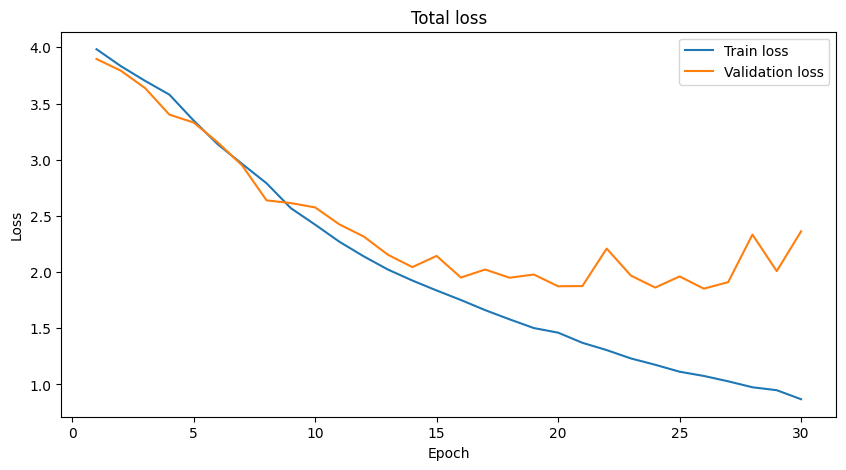

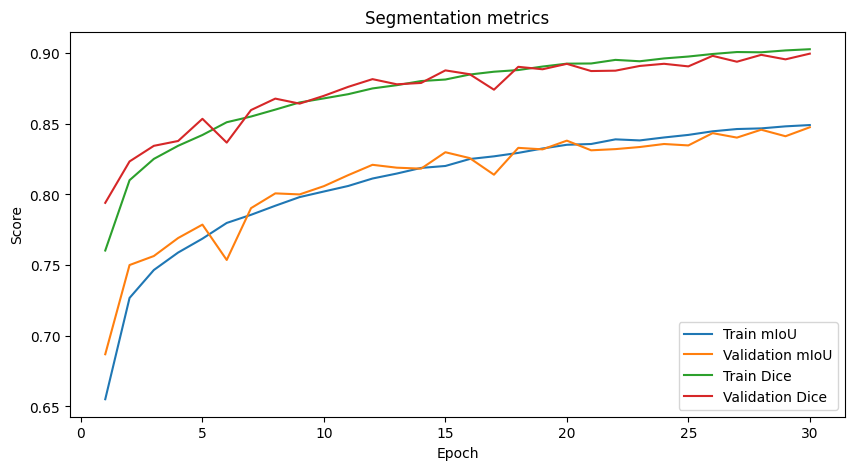

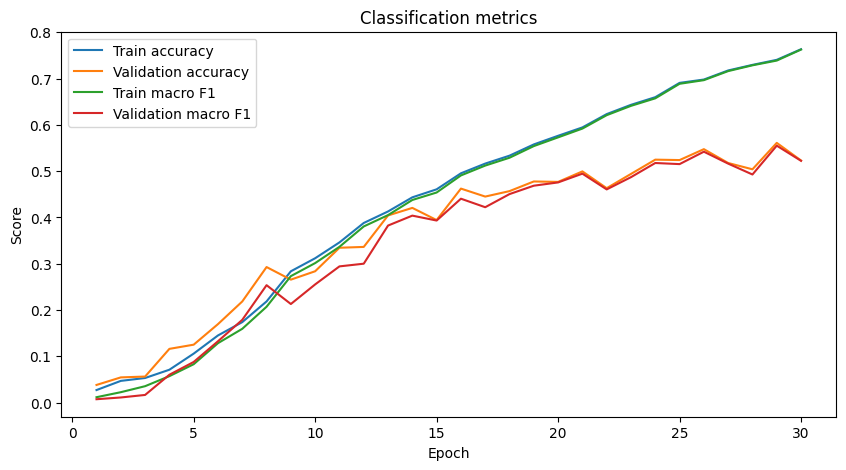

In [ ]:
# Loss/metric curves required for the presentation.
history_df = pd.DataFrame(history)
display(history_df.tail())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history_df["epoch"], history_df["train_loss"], label="Train loss")
ax.plot(history_df["epoch"], history_df["val_loss"], label="Validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Total loss")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history_df["epoch"], history_df["train_miou"], label="Train mIoU")
ax.plot(history_df["epoch"], history_df["val_miou"], label="Validation mIoU")
ax.plot(history_df["epoch"], history_df["train_dice"], label="Train Dice")
ax.plot(history_df["epoch"], history_df["val_dice"], label="Validation Dice")
ax.set_xlabel("Epoch")
ax.set_ylabel("Score")
ax.set_title("Segmentation metrics")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history_df["epoch"], history_df["train_accuracy"], label="Train accuracy")
ax.plot(history_df["epoch"], history_df["val_accuracy"], label="Validation accuracy")
ax.plot(history_df["epoch"], history_df["train_f1_macro"], label="Train macro F1")
ax.plot(history_df["epoch"], history_df["val_f1_macro"], label="Validation macro F1")
ax.set_xlabel("Epoch")
ax.set_ylabel("Score")
ax.set_title("Classification metrics")
ax.legend()
plt.show()


In [ ]:
from pathlib import Path

for p in Path("/content/drive/MyDrive").rglob("*.pt"):
    print(p)

KeyboardInterrupt: 

In [ ]:
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/CSE428_Oxford_Pets")
CHECKPOINT_DIR = BASE_DIR / "checkpoints"

best_path = CHECKPOINT_DIR / "base_unet_best.pt"

print("Checkpoint:", best_path)
print("Exists:", best_path.exists())

Checkpoint: /content/drive/MyDrive/CSE428_Oxford_Pets/checkpoints/base_unet_best.pt
Exists: True


In [ ]:
checkpoint = torch.load(
    best_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

print("Loaded best checkpoint!")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Best validation score:", checkpoint["best_score"])

Loaded best checkpoint!
Checkpoint epoch: 28
Best validation score: 0.6981624560120342


In [ ]:
print(type(history))
print("Number of saved epochs:", len(history))
print("\nFirst epoch:")
print(history[0])

<class 'list'>
Number of saved epochs: 0

First epoch:


IndexError: list index out of range

In [ ]:
history = checkpoint["history"]

for record in history:
    print(
        f"Epoch {record['epoch']:02d} | "
        f"Train loss {record['train_loss']:.4f} | "
        f"Val loss {record['val_loss']:.4f} | "
        f"Val mIoU {record['val_miou']:.4f} | "
        f"Val Dice {record['val_dice']:.4f}"
    )

Epoch 01 | Train loss 3.9830 | Val loss 3.8959 | Val mIoU 0.6869 | Val Dice 0.7940
Epoch 02 | Train loss 3.8328 | Val loss 3.7922 | Val mIoU 0.7500 | Val Dice 0.8234
Epoch 03 | Train loss 3.7013 | Val loss 3.6373 | Val mIoU 0.7564 | Val Dice 0.8344
Epoch 04 | Train loss 3.5790 | Val loss 3.4007 | Val mIoU 0.7691 | Val Dice 0.8378
Epoch 05 | Train loss 3.3481 | Val loss 3.3306 | Val mIoU 0.7786 | Val Dice 0.8535
Epoch 06 | Train loss 3.1349 | Val loss 3.1520 | Val mIoU 0.7536 | Val Dice 0.8367
Epoch 07 | Train loss 2.9614 | Val loss 2.9471 | Val mIoU 0.7903 | Val Dice 0.8597
Epoch 08 | Train loss 2.7901 | Val loss 2.6382 | Val mIoU 0.8007 | Val Dice 0.8678
Epoch 09 | Train loss 2.5684 | Val loss 2.6138 | Val mIoU 0.8000 | Val Dice 0.8642
Epoch 10 | Train loss 2.4218 | Val loss 2.5754 | Val mIoU 0.8059 | Val Dice 0.8698
Epoch 11 | Train loss 2.2695 | Val loss 2.4239 | Val mIoU 0.8136 | Val Dice 0.8761
Epoch 12 | Train loss 2.1397 | Val loss 2.3163 | Val mIoU 0.8210 | Val Dice 0.8816
Epoc

In [ ]:
# Final evaluation using the already-loaded best Base U-Net checkpoint.

print("Using best checkpoint from epoch:", checkpoint["epoch"])
print("Best validation score:", checkpoint["best_score"])

train_eval_loader = OxfordPetBatchLoader(
    df, train_idx, BATCH_SIZE, False,
    augment=False, device=device
)

val_eval_loader = OxfordPetBatchLoader(
    df, val_idx, BATCH_SIZE, False,
    augment=False, device=device
)

test_eval_loader = OxfordPetBatchLoader(
    df, test_idx, BATCH_SIZE, False,
    augment=False, device=device
)

final_results = {}

for split_name, loader in [
    ("Train", train_eval_loader),
    ("Validation", val_eval_loader),
    ("Test", test_eval_loader),
]:
    print(f"Evaluating {split_name}...")

    final_results[split_name] = run_epoch(
        model,
        loader,
        seg_loss_fn,
        cls_loss_fn,
        optimizer=None
    )

summary = pd.DataFrame(final_results).T[
    [
        "miou",
        "dice",
        "pixel_acc",
        "accuracy",
        "precision_macro",
        "recall_macro",
        "f1_macro"
    ]
]

display(summary)

summary.to_csv(
    RESULT_DIR / "base_unet_results.csv"
)

print("Saved:", RESULT_DIR / "base_unet_results.csv")

Using best checkpoint from epoch: 28
Best validation score: 0.6981624560120342
Evaluating Train...
Evaluating Validation...
Evaluating Test...


,miou,dice,pixel_acc,accuracy,precision_macro,recall_macro,f1_macro
Train,0.852838,0.905111,0.928533,0.816061,0.831532,0.816146,0.814815
Validation,0.841179,0.895589,0.920705,0.561197,0.584191,0.561379,0.555146
Test,0.848035,0.900135,0.926417,0.571170,0.595466,0.571551,0.567867


Saved: /content/drive/MyDrive/CSE428_Oxford_Pets/results/base_unet_results.csv


## 16. Required demonstration block

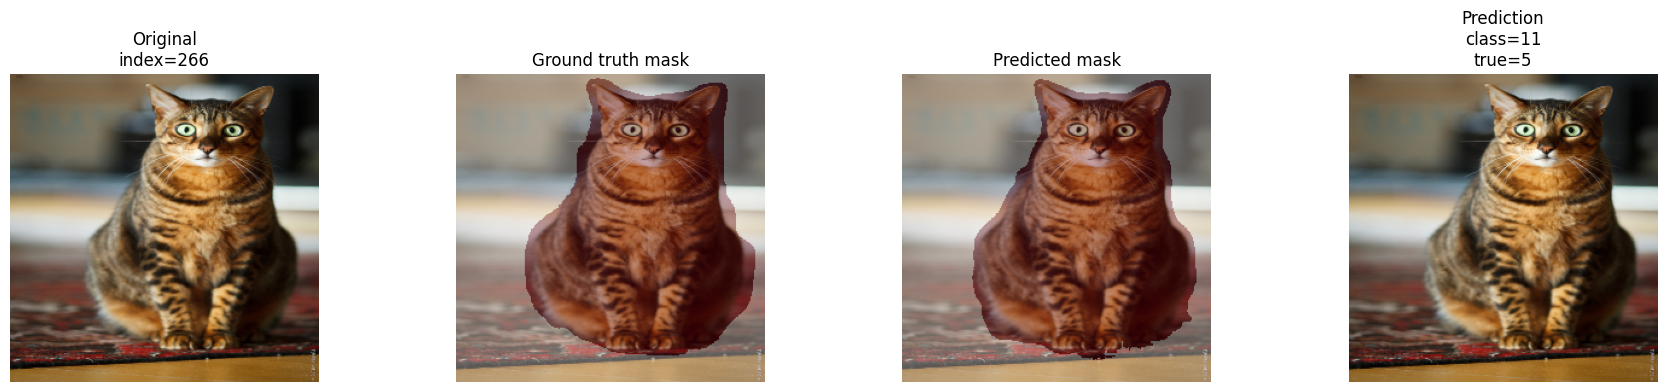

In [ ]:
# Demonstration function.
# Give ANY dataset index; the function runs the model and displays:
# original image, ground-truth overlay, predicted overlay, and classification result.
def predict_index(index, model=model):
    model.eval()
    row = df.iloc[int(index)]
    image, mask = load_pair(row)

    x = torch.tensor(image, dtype=torch.float32, device=device).permute(2, 0, 1).unsqueeze(0)

    with torch.no_grad():
        seg_logits, cls_logits = model(x)
        pred_mask = (torch.sigmoid(seg_logits)[0] >= 0.5).float().cpu().numpy()
        pred_class = int(cls_logits.argmax(dim=1).item())

    fig, axes = plt.subplots(1, 4, figsize=(18, 4))

    axes[0].imshow(image)
    axes[0].axis("off")
    axes[0].set_title(f"Original\nindex={index}")

    axes[1].imshow(image)
    axes[1].imshow(mask, cmap="Reds", alpha=0.35)
    axes[1].axis("off")
    axes[1].set_title("Ground truth mask")

    axes[2].imshow(image)
    axes[2].imshow(pred_mask, cmap="Reds", alpha=0.35)
    axes[2].axis("off")
    axes[2].set_title("Predicted mask")

    axes[3].imshow(image)
    axes[3].axis("off")
    axes[3].set_title(
        f"Prediction\nclass={pred_class}\ntrue={int(row['class_id'])}"
    )

    plt.tight_layout()
    plt.show()

# Example for presentation:
predict_index(int(test_idx[526]))


## Base U-Net checklist

- [x] Oxford-IIIT Pet dataset loading
- [x] Boundary pixels converted to foreground
- [x] Common preprocessing pipeline
- [x] 9 random samples in a 3×3 mask-overlay grid
- [x] Stratified train/validation/test split
- [x] Data augmentation
- [x] Full Base U-Net
- [x] Classifier head attached to encoder/bottleneck output
- [x] Joint segmentation + classification training
- [x] mIoU, Dice, pixel accuracy
- [x] Accuracy, macro precision, macro recall, macro F1
- [x] Train/validation/test result tables
- [x] Per-epoch statistics and loss/metric curves
- [x] Arbitrary-index prediction/demo function
- [x] `torch.save()` checkpoints for Colab interruption/resume

**Important:** the numerical results are produced when you run the training cells on Colab; this notebook does not invent result numbers before training.

In [ ]:
# ============================================================
# INITIALIZE ATTENTION U-NET FROM BASE U-NET
# ============================================================

BATCH_SIZE = 4
EPOCHS = 30

attention_model = MultiTaskAttentionUNet(
    num_classes=37,
    first_out_channel=32
).to(device)

BASE_CHECKPOINT = (
    CHECKPOINT_DIR / "base_unet_best.pt"
)

base_checkpoint = torch.load(
    BASE_CHECKPOINT,
    map_location=device,
    weights_only=False
)

# Recreate Base U-Net architecture
base_model = MultiTaskUNet(
    num_classes=37,
    first_out_channel=32
).to(device)

base_model.load_state_dict(
    base_checkpoint["model_state_dict"]
)

# ------------------------------------------------------------
# Reuse Base U-Net encoder
# ------------------------------------------------------------

attention_model.encoder.load_state_dict(
    base_model.encoder.state_dict()
)

# ------------------------------------------------------------
# Reuse Base U-Net bottleneck
# ------------------------------------------------------------

attention_model.bottleneck.load_state_dict(
    base_model.bottleneck.state_dict()
)

# ------------------------------------------------------------
# Reuse EXACT SAME classifier head
# ------------------------------------------------------------

attention_model.classifier.load_state_dict(
    base_model.classifier.state_dict()
)

print("Base U-Net weights successfully loaded.")
print("✓ Encoder reused")
print("✓ Bottleneck reused")
print("✓ Classifier reused")
print("✓ Attention gates initialized for Attention U-Net")
print("✓ Attention decoder initialized")

NameError: name 'MultiTaskAttentionUNet' is not defined

In [ ]:
# ============================================================
# LOSS FUNCTIONS
# ============================================================

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(37),
    y=df.iloc[train_idx]["class_id"].to_numpy()
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

seg_loss_fn = lambda pred, target: (
    0.5 * nn.BCEWithLogitsLoss()(pred, target)
    +
    0.5 * DiceLoss()(pred, target)
)

cls_loss_fn = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    attention_model.parameters(),
    lr=2e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)

print("Losses, optimizer and scheduler ready.")

In [ ]:
# ============================================================
# DATA LOADERS
# ============================================================

train_loader = OxfordPetBatchLoader(
    df,
    train_idx,
    batch_size=BATCH_SIZE,
    shuffle=True,
    augment=True,
    device=device
)

val_loader = OxfordPetBatchLoader(
    df,
    val_idx,
    batch_size=BATCH_SIZE,
    shuffle=False,
    augment=False,
    device=device
)

test_loader = OxfordPetBatchLoader(
    df,
    test_idx,
    batch_size=BATCH_SIZE,
    shuffle=False,
    augment=False,
    device=device
)

print("Train batches:", train_loader.len)
print("Val batches:  ", val_loader.len)
print("Test batches: ", test_loader.len)

In [ ]:
# ============================================================
# ATTENTION U-NET CHECKPOINTS
# ============================================================

attention_best_path = (
    CHECKPOINT_DIR / "attention_unet_best.pt"
)

attention_last_path = (
    CHECKPOINT_DIR / "attention_unet_last.pt"
)

print("Best checkpoint:")
print(attention_best_path)

print("\nLast checkpoint:")
print(attention_last_path)

In [ ]:
# ============================================================
# RESUME CONFIGURATION
# ============================================================

RESUME = True

start_epoch = 0
history = []
best_score = -np.inf

if RESUME and attention_last_path.exists():

    checkpoint = load_checkpoint(
        attention_last_path,
        attention_model,
        optimizer,
        scheduler
    )

    start_epoch = checkpoint["epoch"] + 1

    history = checkpoint["history"]

    best_score = checkpoint["best_score"]

    print("======================================")
    print("RESUMING ATTENTION U-NET TRAINING")
    print("======================================")

    print("Last completed epoch:",
          checkpoint["epoch"] + 1)

    print("Next epoch:",
          start_epoch + 1)

    print("Saved history entries:",
          len(history))

    print("Best score:",
          best_score)

else:

    print("======================================")
    print("STARTING ATTENTION U-NET FROM SCRATCH")
    print("======================================")

In [ ]:
# ============================================================
# TRAIN ATTENTION U-NET
# ============================================================

if device != "cuda":

    raise RuntimeError(
        "GPU is not available. Do not start Attention U-Net "
        "training on CPU. Reconnect with a GPU runtime and "
        "run this cell again."
    )

for epoch in range(start_epoch, EPOCHS):

    train_metrics = run_epoch(
        attention_model,
        train_loader,
        seg_loss_fn,
        cls_loss_fn,
        optimizer,
        seg_weight=1.0,
        cls_weight=1.0
    )

    val_metrics = run_epoch(
        attention_model,
        val_loader,
        seg_loss_fn,
        cls_loss_fn,
        optimizer=None,
        seg_weight=1.0,
        cls_weight=1.0
    )

    # --------------------------------------------------------
    # Selection score
    # --------------------------------------------------------

    selection_score = (
        0.5 * val_metrics["miou"]
        +
        0.5 * val_metrics["f1_macro"]
    )

    scheduler.step(selection_score)

    # --------------------------------------------------------
    # Update history
    # --------------------------------------------------------

    record = {
        "epoch": epoch + 1
    }

    record.update({
        f"train_{k}": v
        for k, v in train_metrics.items()
    })

    record.update({
        f"val_{k}": v
        for k, v in val_metrics.items()
    })

    history.append(record)

    # --------------------------------------------------------
    # Update best score BEFORE saving
    # --------------------------------------------------------

    is_best = selection_score > best_score

    if is_best:
        best_score = selection_score

    # --------------------------------------------------------
    # Save LAST checkpoint every epoch
    # --------------------------------------------------------

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": attention_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "history": history,
        "best_score": best_score
    }

    torch.save(
        checkpoint,
        attention_last_path
    )

    # --------------------------------------------------------
    # Save BEST checkpoint
    # --------------------------------------------------------

    if is_best:

        torch.save(
            checkpoint,
            attention_best_path
        )

        print("  ✓ New best checkpoint saved.")

    # --------------------------------------------------------
    # Epoch output
    # --------------------------------------------------------

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train loss {train_metrics['loss']:.4f} | "
        f"Val loss {val_metrics['loss']:.4f} | "
        f"Val mIoU {val_metrics['miou']:.4f} | "
        f"Val Dice {val_metrics['dice']:.4f} | "
        f"Val pixel acc {val_metrics['pixel_acc']:.4f} | "
        f"Val acc {val_metrics['accuracy']:.4f} | "
        f"Val F1 {val_metrics['f1_macro']:.4f}"
    )

print("======================================")
print("ATTENTION U-NET TRAINING FINISHED")
print("======================================")

In [ ]:
history_df = pd.DataFrame(history)

display(history_df.tail())

print("Total recorded epochs:",
      len(history_df))

print("Best validation mIoU:",
      history_df["val_miou"].max())

print("Best validation Dice:",
      history_df["val_dice"].max())

print("Best validation accuracy:",
      history_df["val_accuracy"].max())

print("Best validation F1:",
      history_df["val_f1_macro"].max())

In [ ]:
# ============================================================
# LOSS CURVE
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Attention U-Net Training and Validation Loss")

plt.legend()
plt.grid()

plt.show()

In [ ]:
# ============================================================
# SEGMENTATION CURVES
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_miou"],
    label="Train mIoU"
)

plt.plot(
    history_df["epoch"],
    history_df["val_miou"],
    label="Validation mIoU"
)

plt.plot(
    history_df["epoch"],
    history_df["train_dice"],
    label="Train Dice"
)

plt.plot(
    history_df["epoch"],
    history_df["val_dice"],
    label="Validation Dice"
)

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Attention U-Net Segmentation Performance")

plt.legend()
plt.grid()

plt.show()

In [ ]:
# ============================================================
# CLASSIFICATION CURVES
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    label="Train Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Validation Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["train_f1_macro"],
    label="Train Macro F1"
)

plt.plot(
    history_df["epoch"],
    history_df["val_f1_macro"],
    label="Validation Macro F1"
)

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Attention U-Net Classification Performance")

plt.legend()
plt.grid()

plt.show()

In [ ]:
# ============================================================
# FINAL ATTENTION U-NET EVALUATION
# ============================================================

best_checkpoint = torch.load(
    attention_best_path,
    map_location=device,
    weights_only=False
)

attention_model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

print(
    "Loaded best Attention U-Net checkpoint."
)

print(
    "Best checkpoint epoch:",
    best_checkpoint["epoch"] + 1
)

print(
    "Best validation selection score:",
    best_checkpoint["best_score"]
)

In [ ]:
train_eval_loader = OxfordPetBatchLoader(
    df,
    train_idx,
    BATCH_SIZE,
    False,
    augment=False,
    device=device
)

val_eval_loader = OxfordPetBatchLoader(
    df,
    val_idx,
    BATCH_SIZE,
    False,
    augment=False,
    device=device
)

test_eval_loader = OxfordPetBatchLoader(
    df,
    test_idx,
    BATCH_SIZE,
    False,
    augment=False,
    device=device
)

final_results = {}

for split_name, loader in [
    ("Train", train_eval_loader),
    ("Validation", val_eval_loader),
    ("Test", test_eval_loader),
]:

    print(f"Evaluating {split_name}...")

    final_results[split_name] = run_epoch(
        attention_model,
        loader,
        seg_loss_fn,
        cls_loss_fn,
        optimizer=None
    )

summary = pd.DataFrame(
    final_results
).T[
    [
        "miou",
        "dice",
        "pixel_acc",
        "accuracy",
        "precision_macro",
        "recall_macro",
        "f1_macro"
    ]
]

display(summary)

summary.to_csv(
    RESULT_DIR / "attention_unet_results.csv"
)

print(
    "Saved:",
    RESULT_DIR / "attention_unet_results.csv"
)

In [ ]:
# ============================================================
# ATTENTION U-NET DEMONSTRATION
# ============================================================

def predict_attention_index(index):

    attention_model.eval()

    row = df.iloc[int(index)]

    image, mask = load_pair(row)

    x = torch.tensor(
        image,
        dtype=torch.float32,
        device=device
    )

    x = x.permute(
        2, 0, 1
    ).unsqueeze(0)

    with torch.no_grad():

        seg_logits, cls_logits = attention_model(x)

        pred_mask = (
            torch.sigmoid(seg_logits)[0] >= 0.5
        ).float().cpu().numpy()

        pred_class = int(
            cls_logits.argmax(dim=1).item()
        )

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(18, 4)
    )

    # Original
    axes[0].imshow(image)
    axes[0].axis("off")
    axes[0].set_title(
        f"Original\nindex={index}"
    )

    # Ground truth
    axes[1].imshow(image)
    axes[1].imshow(
        mask,
        cmap="Reds",
        alpha=0.35
    )
    axes[1].axis("off")
    axes[1].set_title(
        "Ground truth mask"
    )

    # Prediction
    axes[2].imshow(image)
    axes[2].imshow(
        pred_mask,
        cmap="Reds",
        alpha=0.35
    )
    axes[2].axis("off")
    axes[2].set_title(
        "Attention U-Net predicted mask"
    )

    # Classification
    axes[3].imshow(image)
    axes[3].axis("off")
    axes[3].set_title(
        f"Prediction\n"
        f"class={pred_class}\n"
        f"true={int(row['class_id'])}"
    )

    plt.tight_layout()
    plt.show()

In [ ]:
rng = np.random.default_rng(428)

demo_indices = rng.choice(
    len(df),
    size=9,
    replace=False
)

print("Demo indices:", demo_indices)

for idx in demo_indices:
    predict_attention_index(int(idx))

In [ ]:
# ============================================================
# BASE U-NET VS ATTENTION U-NET
# ============================================================

base_results = pd.read_csv(
    RESULT_DIR / "base_unet_results.csv",
    index_col=0
)

attention_results = pd.read_csv(
    RESULT_DIR / "attention_unet_results.csv",
    index_col=0
)

comparison = pd.concat(
    {
        "Base U-Net": base_results,
        "Attention U-Net": attention_results
    },
    axis=0
)

display(comparison)